# Задание 3.3

**(Задача о цепной линии)** Исследовать форму равновесия однородной тяжёлой нерастяжимой нити (цепи), подвешенной за два конца, под действием силы тяжести.

1) В ноутбуке (файл Jupyter Notebook) в разметке Markdown (LaTeX) привести подробное аналитическое решение (вывод дифференциального уравнения, его решение);
2) Привести статическую картинку в формате png (pdf) решения задачи (код на Jupyter Notebook, который создаёт рисунок);
3) Используя инструментарий Jupyter Notebook, привести анимацию данного решения.

**Детализация задания.** *Цель:* исследовать и визуализировать форму цепной линии — кривой равновесия тяжёлой гибкой нити.

- **Аналитическое решение:** вывести дифференциальное уравнение из условий равновесия элемента цепи; решить его методом разделения переменных; получить уравнение цепной линии $y=a\,\mathrm{ch}(x/a)$; проанализировать физический смысл параметра $a$.
- **Статическая визуализация:** график цепной линии для различных значений $a$; показать геометрические и физические свойства кривой; сетка, подписи осей, легенда; сохранить рисунок в png.
- **Анимация:** `FuncAnimation`; изменение формы цепи при варьировании параметров; зависимость провисания от натяжения и плотности; силы, действующие на элементы цепи.

## Теория

**1. Равновесие элемента цепи.** Ось $x$ — горизонталь, ось $y$ — вертикаль вверх. Цепь однородна, $\rho$ — линейная плотность (кг/м), $y=y(x)$ — форма цепи. Нить гибкая, поэтому сила натяжения $T$ направлена по касательной. Обозначим через $\varphi$ угол касательной с осью $x$: $\operatorname{tg}\varphi=y'$.

Рассмотрим элемент цепи между $x$ и $x+dx$, длина $ds=\sqrt{1+y'^2}\,dx$. На него действуют натяжения на концах (влево в точке $x$, вправо в точке $x+dx$) и вес $\rho g\,ds$:

$$
\text{по }x:\quad (T\cos\varphi)\big|_{x+dx}-(T\cos\varphi)\big|_{x}=0,\qquad
\text{по }y:\quad (T\sin\varphi)\big|_{x+dx}-(T\sin\varphi)\big|_{x}=\rho g\,ds .
$$

Из первого уравнения **горизонтальная составляющая натяжения постоянна**: $T\cos\varphi=H=\mathrm{const}$. Тогда $T\sin\varphi=H\operatorname{tg}\varphi=Hy'$, и второе уравнение даёт $H\,dy'=\rho g\sqrt{1+y'^2}\,dx$:

$$
\boxed{\ y''=\frac1a\sqrt{1+y'^2},\qquad a=\frac{H}{\rho g}\ }
$$

**2. Решение методом разделения переменных.** Уравнение не содержит $y$, поэтому делаем замену $p=y'$:

$$
\frac{dp}{\sqrt{1+p^2}}=\frac{dx}{a}\ \Longrightarrow\ \operatorname{arsh}p=\frac{x-x_0}{a}\ \Longrightarrow\ y'=\operatorname{sh}\frac{x-x_0}{a}\ \Longrightarrow\ y=a\,\operatorname{ch}\frac{x-x_0}{a}+C .
$$

Выберем начало координат так, чтобы нижняя точка (вершина) была в $(0,a)$, т.е. $x_0=0$, $C=0$:

$$
\boxed{\ y=a\,\operatorname{ch}\frac{x}{a}\ }\qquad(\text{цепная линия}).
$$

**3. Физический смысл параметра $a$.**
- $a=H/(\rho g)$ — длина куска цепи, вес которого равен горизонтальному натяжению $H$.
- $a$ — радиус кривизны в вершине: $k(0)=\dfrac{y''}{(1+y'^2)^{3/2}}\Big|_{x=0}=\dfrac1a$.
- Чем больше натяжение $H$ или чем легче цепь (меньше $\rho$), тем больше $a$ и тем более пологая цепь. **Форма зависит только от отношения $H/\rho$.**

**4. Свойства цепной линии.**
- Длина дуги от вершины: $s=\displaystyle\int_0^x\operatorname{ch}\frac{\xi}{a}\,d\xi=a\,\operatorname{sh}\frac xa$, откуда $y^2=a^2+s^2$.
- Натяжение: $T=\dfrac{H}{\cos\varphi}=H\sqrt{1+y'^2}=H\operatorname{ch}\dfrac xa=\rho g\,y$. Натяжение в точке равно весу куска цепи длины $y$ (высота над осью $x$, «директрисой»). Максимум натяжения — в точках подвеса.
- Цепь длины $\ell$, подвешенная в точках $(\pm L,\,h)$: $\ \ell=2a\operatorname{sh}\dfrac La$ — трансцендентное уравнение для $a$. Провисание $f=a\left(\operatorname{ch}\dfrac La-1\right)$. Натяжение в опорах $T_{\max}=H\operatorname{ch}\dfrac La$.
- При малом провисании ($L\ll a$): $\operatorname{ch}\frac xa\approx1+\frac{x^2}{2a^2}$, и цепная линия близка к параболе $y\approx a+\frac{x^2}{2a}$, $f\approx\frac{L^2}{2a}=\frac{\rho gL^2}{2H}$.
- Вариационный смысл: среди кривых данной длины с данными концами цепная линия минимизирует потенциальную энергию $\rho g\int y\,ds$, т.е. центр тяжести цепи занимает самое низкое положение.

**Что делаем в коде.** Проверяем аналитическое решение численным интегрированием ОДУ (`scipy.integrate.solve_ivp`). По длине цепи находим $a$ (`scipy.optimize.brentq`). Рисуем семейство $y=a\,\mathrm{ch}(x/a)$, окружность кривизны в вершине, сравнение с параболой и векторы натяжения: у всех векторов одинаковая горизонтальная составляющая $H$. В анимации сначала меняется натяжение $H$ (при фиксированной $\rho$), затем плотность $\rho$ (при фиксированном $H$). Цепь окрашена по величине натяжения, для одного элемента показана диаграмма сил (два натяжения и вес, их сумма равна нулю), в опорах — реакции. Анимация встроена через `to_jshtml()` (проигрыватель с паузой и шагом).

a = 0.5: max |y_числ - a·ch(x/a)| = 1.0e-08
a = 1.0: max |y_числ - a·ch(x/a)| = 4.8e-10
a = 2.0: max |y_числ - a·ch(x/a)| = 1.6e-10

  ℓ      a=H/(ρg)   провисание f   T_max/(ρg)
 4.4     2.6199        0.8012       3.4211
 5.0     1.6910        1.3272       3.0182
 6.0     1.2329        2.0105       3.2435
 8.0     0.9186        3.1856       4.1041


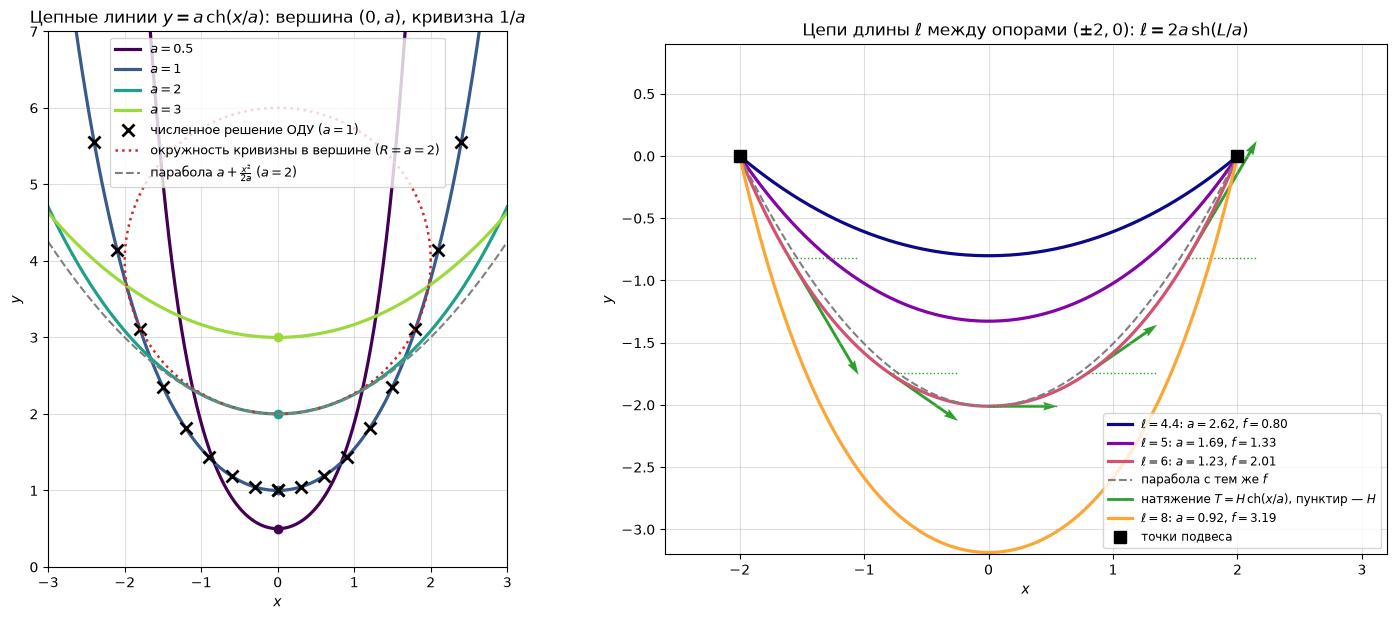

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from IPython.display import HTML, display

g = 9.81


def catenary(x, a):
    """Цепная линия с вершиной в (0, a): y = a·ch(x/a)."""
    return a*np.cosh(x/a)


def a_from_length(ell, L):
    """Параметр a по длине цепи ell и полупролёту L: решаем 2a·sh(L/a) = ell."""
    return brentq(lambda a: 2*a*np.sinh(L/a) - ell, 1e-2, 1e4)


# ---------- Проверка: численное решение ОДУ y'' = √(1+y'²)/a совпадает с a·ch(x/a) ----------
for a in (0.5, 1.0, 2.0):
    sol = solve_ivp(lambda x, u: [u[1], np.sqrt(1 + u[1]**2)/a], [0, 3], [a, 0.0],   # y(0)=a, y'(0)=0
                    dense_output=True, rtol=1e-10, atol=1e-12)
    xs = np.linspace(0, 3, 301)
    print(f"a = {a}: max |y_числ - a·ch(x/a)| = {np.max(np.abs(sol.sol(xs)[0] - catenary(xs, a))):.1e}")

# ---------- Статический рисунок ----------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.3))

# (а) семейство y = a·ch(x/a) для разных a
x = np.linspace(-3, 3, 601)
for a, col in zip([0.5, 1.0, 2.0, 3.0], plt.cm.viridis(np.linspace(0, 0.85, 4))):
    ax1.plot(x, catenary(x, a), color=col, lw=2.3, label=f"$a={a:g}$")
    ax1.plot(0, a, "o", color=col, ms=6)                                   # вершина (0, a)
# численное решение ОДУ (a = 1) — маркеры
sol = solve_ivp(lambda x, u: [u[1], np.sqrt(1 + u[1]**2)], [0, 2.4], [1.0, 0.0], dense_output=True, rtol=1e-10)
xm = np.linspace(0, 2.4, 9)
ax1.plot(np.r_[-xm[::-1], xm], np.r_[sol.sol(xm[::-1])[0], sol.sol(xm)[0]], "kx", ms=8, mew=2,
         label="численное решение ОДУ ($a=1$)")
# окружность кривизны в вершине (a = 2): радиус равен a
a = 2.0
phi = np.linspace(0, 2*np.pi, 300)
ax1.plot(a*np.cos(phi), 2*a + a*np.sin(phi), ":", color="tab:red", lw=1.8, label="окружность кривизны в вершине ($R=a=2$)")
# парабола y = a + x²/(2a) — приближение при малых |x|/a
ax1.plot(x, a + x**2/(2*a), "--", color="gray", lw=1.5, label=r"парабола $a+\frac{x^2}{2a}$ ($a=2$)")
ax1.set(xlim=(-3, 3), ylim=(0, 7), xlabel="$x$", ylabel="$y$", aspect="equal",
        title=r"Цепные линии $y=a\,\mathrm{ch}(x/a)$: вершина $(0,a)$, кривизна $1/a$")
ax1.grid(alpha=0.4); ax1.legend(loc="upper center", fontsize=9)

# (б) цепи разной длины между опорами (±L, 0); векторы натяжения для одной из них
L = 2.0
print("\n  ℓ      a=H/(ρg)   провисание f   T_max/(ρg)")
for ell, col in zip([4.4, 5.0, 6.0, 8.0], plt.cm.plasma(np.linspace(0, 0.8, 4))):
    a = a_from_length(ell, L)
    f = a*(np.cosh(L/a) - 1)
    xx = np.linspace(-L, L, 400)
    ax2.plot(xx, a*(np.cosh(xx/a) - np.cosh(L/a)), color=col, lw=2.3, label=rf"$\ell={ell:g}$: $a={a:.2f}$, $f={f:.2f}$")
    print(f"{ell:4.1f}   {a:8.4f}   {f:11.4f}   {a*np.cosh(L/a):10.4f}")
    if ell == 6.0:
        # парабола с тем же провисанием — для сравнения формы
        ax2.plot(xx, -f*(1 - xx**2/L**2), "--", color="gray", lw=1.5, label="парабола с тем же $f$")
        # натяжение T = H·ch(x/a) по касательной; горизонтальная составляющая всюду = H (здесь ρg = 1 ⇒ H = a)
        k = 0.45                                       # масштаб стрелок
        for xp in (-1.6, -0.8, 0.0, 0.8, 1.6):
            yp = a*(np.cosh(xp/a) - np.cosh(L/a))
            T = a*np.cosh(xp/a)
            tx, ty = 1/np.cosh(xp/a), np.tanh(xp/a)     # единичный касательный вектор (cos φ, sin φ)
            ax2.quiver(xp, yp, k*T*tx, k*T*ty, angles="xy", scale_units="xy", scale=1, color="tab:green", width=0.004)
            ax2.plot([xp, xp + k*a], [yp, yp], color="tab:green", lw=1, ls=":")
        ax2.plot([], [], color="tab:green", lw=2, label=r"натяжение $T=H\,\mathrm{ch}(x/a)$, пунктир — $H$")
ax2.plot([-L, L], [0, 0], "ks", ms=9, label="точки подвеса")
ax2.set(xlim=(-2.6, 3.2), ylim=(-3.2, 0.9), xlabel="$x$", ylabel="$y$", aspect="equal",
        title=r"Цепи длины $\ell$ между опорами $(\pm2,0)$: $\ell=2a\,\mathrm{sh}(L/a)$")
ax2.grid(alpha=0.4); ax2.legend(loc="lower right", fontsize=8.5)

fig.tight_layout()
fig.savefig("3.3.png", dpi=150)          # сохраняем статическую картинку
plt.show()

# ---------- Анимация: варьируем натяжение H, затем плотность ρ ----------
n1 = n2 = 60
s1 = (1 - np.cos(np.linspace(0, np.pi, n1)))/2           # плавный переход 0 → 1
s2 = (1 - np.cos(np.linspace(0, np.pi, n2)))/2
H_fr = np.r_[15 + 45*s1, np.full(n2, 30.0)]              # фаза 1: H = 15 → 60 Н при ρ = 1.5 кг/м
rho_fr = np.r_[np.full(n1, 1.5), 0.5 + 2.5*s2]           # фаза 2: ρ = 0.5 → 3 кг/м при H = 30 Н
a_fr = H_fr/(rho_fr*g)

x = np.linspace(-L, L, 300)
x1, x2 = 0.7, 1.15                                       # выделенный элемент цепи
k = 0.03                                                 # масштаб стрелок, м/Н
Tmax_all = np.max(H_fr*np.cosh(L/a_fr))

fig, (ax, axf) = plt.subplots(1, 2, figsize=(13, 5.2), dpi=65, gridspec_kw=dict(width_ratios=[1.6, 1]))
norm = Normalize(0, Tmax_all)
lc = LineCollection([], cmap="plasma", norm=norm, lw=4)
ax.add_collection(lc)
cb = fig.colorbar(lc, ax=ax, fraction=0.04, pad=0.02); cb.set_label("натяжение $T$, Н")
elem, = ax.plot([], [], color="k", lw=5, alpha=0.5, label="выделенный элемент")
q_T = ax.quiver([0, 0], [0, 0], [0, 0], [0, 0], angles="xy", scale_units="xy", scale=1, color="tab:green", width=0.005)
q_P = ax.quiver([0], [0], [0], [0], angles="xy", scale_units="xy", scale=1, color="tab:blue", width=0.005)
q_R = ax.quiver([-L, L], [0, 0], [0, 0], [0, 0], angles="xy", scale_units="xy", scale=1, color="tab:red", width=0.005)
ax.plot([-L, L], [0, 0], "ks", ms=10)
ax.plot([], [], color="tab:green", lw=2, label="натяжения на концах элемента")
ax.plot([], [], color="tab:blue", lw=2, label=r"вес элемента $\rho g\,\Delta s$")
ax.plot([], [], color="tab:red", lw=2, label="реакции опор ($T_{\max}$)")
ax.set(xlim=(-4.3, 4.3), ylim=(-3.1, 2.4), aspect="equal", xlabel="$x$, м", ylabel="$y$, м")
ax.grid(alpha=0.3); ax.legend(loc="upper center", fontsize=9, ncol=2)
title = ax.set_title("")

# правая панель: провисание зависит только от a = H/(ρg)
aa = np.linspace(0.9, 7, 300)
axf.plot(aa, aa*(np.cosh(L/aa) - 1), "k-", lw=2, label=r"$f=a\,(\mathrm{ch}(L/a)-1)$")
axf.plot(aa, L**2/(2*aa), "--", color="gray", label=r"$f\approx \rho g L^2/(2H)$")
mark, = axf.plot([], [], "o", color="tab:red", ms=11)
axf.set(xlabel=r"$a=H/(\rho g)$, м", ylabel="провисание $f$, м", title="Провисание: $f$ убывает с ростом $H/\\rho$",
        ylim=(0, 3.2))
axf.grid(alpha=0.4); axf.legend()
info = axf.text(0.3, 0.72, "", transform=axf.transAxes, va="top", family="monospace", fontsize=10,
                bbox=dict(boxstyle="round", fc="white", alpha=0.9))


def update(i):
    H, rho, a = H_fr[i], rho_fr[i], a_fr[i]
    c0 = np.cosh(L/a)
    y = a*(np.cosh(x/a) - c0)                                  # цепь между опорами (±L, 0)
    T = H*np.cosh(x/a)                                         # натяжение вдоль цепи
    pts = np.column_stack([x, y]).reshape(-1, 1, 2)
    lc.set_segments(np.concatenate([pts[:-1], pts[1:]], axis=1))
    lc.set_array(0.5*(T[:-1] + T[1:]))
    # диаграмма сил для элемента [x1, x2]: натяжения по касательным наружу и вес вниз
    xe = np.linspace(x1, x2, 30)
    elem.set_data(xe, a*(np.cosh(xe/a) - c0))
    y1, y2 = a*(np.cosh(x1/a) - c0), a*(np.cosh(x2/a) - c0)
    T1 = H*np.array([-1, -np.sinh(x1/a)])                    # на левом конце: тянет влево вдоль касательной
    T2 = H*np.array([1, np.sinh(x2/a)])                      # на правом конце: тянет вправо
    ds = a*(np.sinh(x2/a) - np.sinh(x1/a))
    P = np.array([0, -rho*g*ds])                              # вес элемента
    q_T.set_offsets([[x1, y1], [x2, y2]]); q_T.set_UVC(k*np.array([T1[0], T2[0]]), k*np.array([T1[1], T2[1]]))
    xm = 0.5*(x1 + x2)
    q_P.set_offsets([[xm, a*(np.cosh(xm/a) - c0)]]); q_P.set_UVC([0], [k*P[1]])
    # реакции опор: равны натяжению на концах, направлены по касательной наружу
    q_R.set_UVC(k*H*np.array([-1, 1]), k*H*np.sinh(L/a)*np.array([1, 1]))
    resid = np.linalg.norm(T1 + T2 + P)                       # проверка равновесия элемента: ΣF = 0
    f, ell = a*(c0 - 1), 2*a*np.sinh(L/a)
    mark.set_data([a], [f])
    phase = "1: меняем натяжение H" if i < n1 else "2: меняем плотность ρ"
    title.set_text(f"Фаза {phase}")
    info.set_text(f"H     = {H:5.1f} Н\nρ     = {rho:5.2f} кг/м\na     = {a:5.2f} м\nf     = {f:5.2f} м\n"
                  f"длина = {ell:5.2f} м\nT_max = {H*c0:5.1f} Н\n|ΣF| элемента = {resid:.0e}")
    return lc, elem, q_T, q_P, q_R, mark, info, title


anim = FuncAnimation(fig, update, frames=n1 + n2, interval=60)
fig.tight_layout()
plt.close(fig)
display(HTML(anim.to_jshtml(default_mode="reflect")))   # проигрыватель: пуск/пауза, шаг, скорость